In [1]:
import os, glob, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report, roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'
def trouver(nom):
    # 1) à côté du notebook, 2) dans ../ml/data du projet, 3) n'importe où dans Téléchargements
    for chemin in [nom, os.path.join('..', 'ml', 'data', nom)]:
        if os.path.exists(chemin):
            return os.path.abspath(chemin)
    dossier = os.path.join(os.path.expanduser('~'), 'Downloads')
    res = glob.glob(os.path.join(dossier, '**', nom), recursive=True)
    if not res:
        raise FileNotFoundError(f'{nom} introuvable (ni dans ml/data, ni dans {dossier})')
    return res[0]

F_DATA = trouver('dataset_risque_blessure.csv')
try:
    F_BLESSURES = trouver('blessures.csv')
except FileNotFoundError:
    F_BLESSURES = None
print(F_DATA)
print(F_BLESSURES)

C:\Users\lenovo\Downloads\dataset_risque_blessure.csv
C:\Users\lenovo\Downloads\blessures.csv


In [2]:
df = pd.read_csv(F_DATA)
blessures = pd.read_csv(F_BLESSURES, parse_dates=['from_date']) if F_BLESSURES else None
print(df.shape)
df.head()

(175062, 21)


,player,mois,league,team,matchs_30j,matchs_90j,titularisations_90j,jours_depuis_dernier_match,note_moy_5,note_moy_saison,...,nb_blessures_365j,jours_absence_365j,nb_blessures_graves_avant,jours_depuis_derniere_blessure,jours_absence_mois_suivant,height,main_position,foot,age,risque
0,Aaron Connolly,2019-09,EPL,Brighton,1,1,0,1,5.860,5.860,...,1,78.0,1,152.0,0.0,174.0,Attack,right,19.6,aucun
1,Aaron Connolly,2019-10,EPL,Brighton,3,4,0,3,6.060,6.060,...,1,78.0,1,182.0,0.0,174.0,Attack,right,19.7,aucun
2,Aaron Connolly,2019-11,EPL,Brighton,3,7,3,6,6.892,6.627,...,1,78.0,1,213.0,0.0,174.0,Attack,right,19.8,aucun
3,Aaron Connolly,2019-12,EPL,Brighton,3,9,6,1,6.394,6.526,...,1,78.0,1,243.0,14.0,174.0,Attack,right,19.8,moyen
4,Aaron Connolly,2020-01,EPL,Brighton,3,9,8,6,6.036,6.427,...,2,92.0,1,12.0,0.0,174.0,Attack,right,19.9,aucun


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175062 entries, 0 to 175061
Data columns (total 21 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   player                          175062 non-null  object 
 1   mois                            175062 non-null  object 
 2   league                          175062 non-null  object 
 3   team                            175062 non-null  object 
 4   matchs_30j                      175062 non-null  int64  
 5   matchs_90j                      175062 non-null  int64  
 6   titularisations_90j             175062 non-null  int64  
 7   jours_depuis_dernier_match      175062 non-null  int64  
 8   note_moy_5                      175062 non-null  float64
 9   note_moy_saison                 175062 non-null  float64
 10  nb_blessures_avant              175062 non-null  int64  
 11  nb_blessures_365j               175062 non-null  int64  
 12  jours_absence_36

In [4]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
matchs_30j,175062.0,2.14,1.68,0.00,0.00,2.00,3.00,16.00
matchs_90j,175062.0,6.20,3.56,1.00,3.00,6.00,9.00,33.00
titularisations_90j,175062.0,4.76,3.71,0.00,1.00,4.00,8.00,31.00
jours_depuis_dernier_match,175062.0,20.58,23.65,1.00,4.00,10.00,31.00,90.00
note_moy_5,175062.0,6.65,0.43,4.18,6.33,6.61,6.91,9.77
note_moy_saison,175062.0,6.69,0.33,4.18,6.48,6.68,6.88,9.77
nb_blessures_avant,175062.0,3.41,4.23,0.00,0.00,2.00,5.00,40.00
nb_blessures_365j,175062.0,0.88,1.17,0.00,0.00,0.00,1.00,11.00
jours_absence_365j,175062.0,21.99,37.31,0.00,0.00,0.00,31.00,703.00
nb_blessures_graves_avant,175062.0,1.08,1.49,0.00,0.00,1.00,2.00,15.00


risque
aucun     90.7
faible     1.6
moyen      4.5
fort       3.2
Name: count, dtype: float64


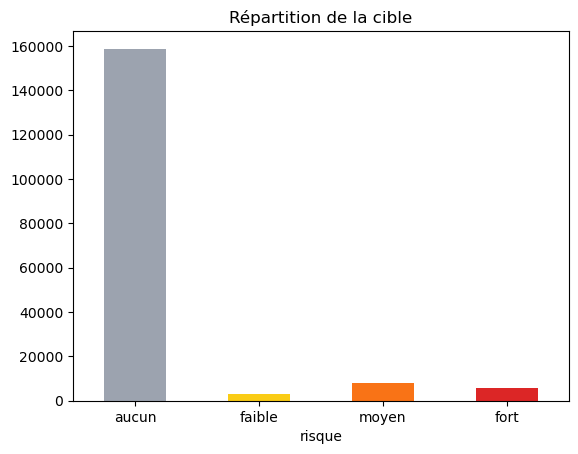

In [5]:
ordre = ['aucun', 'faible', 'moyen', 'fort']
rep = df['risque'].value_counts().reindex(ordre)
print((rep / len(df) * 100).round(1))
rep.plot.bar(color=['#9ca3af', '#facc15', '#f97316', '#dc2626'])
plt.title('Répartition de la cible')
plt.xticks(rotation=0)
plt.show()

In [6]:
train = df[df['mois'] < '2020-07'].copy()
valid = df[(df['mois'] >= '2020-07') & (df['mois'] < '2021-07')].copy()
test = df[df['mois'] >= '2021-07'].copy()
for nom, d in [('train', train), ('valid', valid), ('test', test)]:
    print(nom, len(d), round((d['risque'] != 'aucun').mean(), 3))

train 110860 0.094
valid 20929 0.1
test 43273 0.087


C:\Users\lenovo\AppData\Local\Temp\ipykernel_6552\514346445.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  exp.groupby(pd.cut(exp['age'], [15, 21, 24, 27, 30, 33, 45]))['blesse'].mean().plot.bar(ax=axes[0, 0], title='Âge')


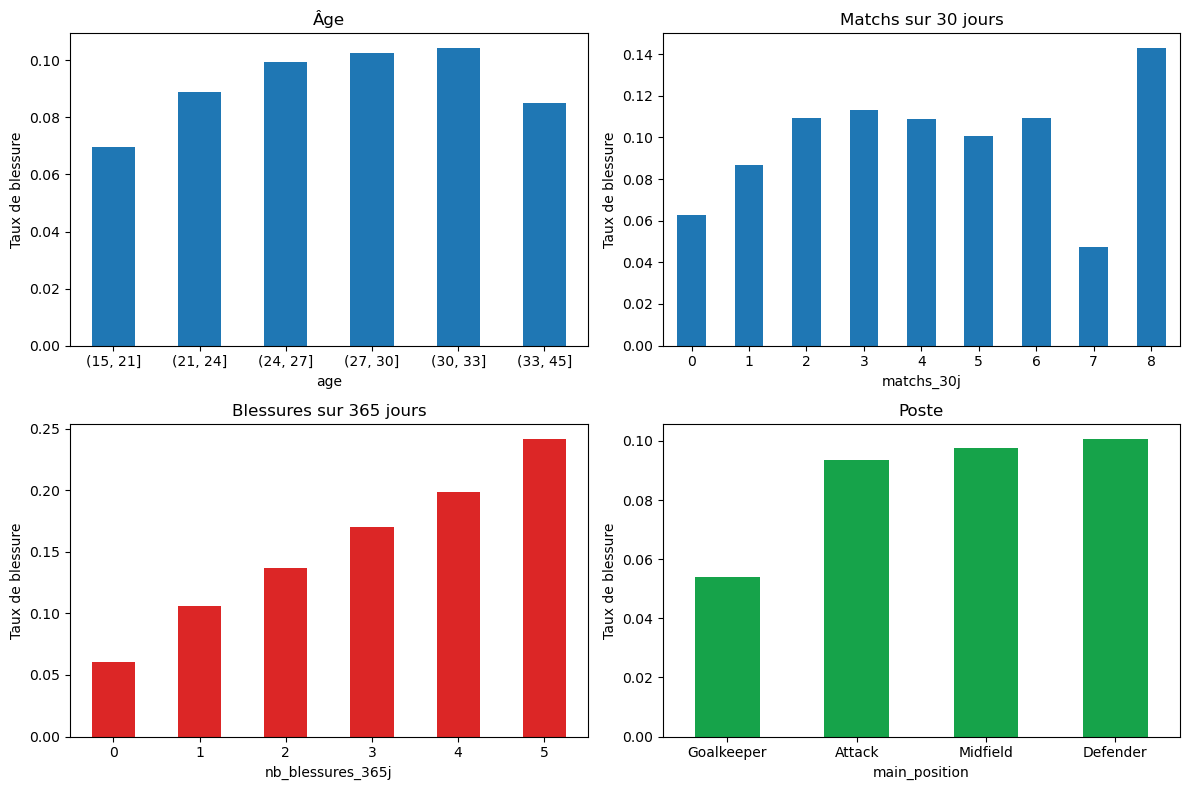

In [7]:
exp = train.copy()
exp['blesse'] = (exp['risque'] != 'aucun').astype(int)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
exp.groupby(pd.cut(exp['age'], [15, 21, 24, 27, 30, 33, 45]))['blesse'].mean().plot.bar(ax=axes[0, 0], title='Âge')
exp.groupby(exp['matchs_30j'].clip(upper=8))['blesse'].mean().plot.bar(ax=axes[0, 1], title='Matchs sur 30 jours')
exp.groupby(exp['nb_blessures_365j'].clip(upper=5))['blesse'].mean().plot.bar(ax=axes[1, 0], title='Blessures sur 365 jours', color='#dc2626')
exp.groupby('main_position')['blesse'].mean().sort_values().plot.bar(ax=axes[1, 1], title='Poste', color='#16a34a')
for ax in axes.flat:
    ax.set_ylabel('Taux de blessure')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [8]:
num_cols = ['matchs_30j', 'matchs_90j', 'titularisations_90j', 'jours_depuis_dernier_match',
            'note_moy_5', 'note_moy_saison', 'nb_blessures_avant', 'nb_blessures_365j',
            'jours_absence_365j', 'nb_blessures_graves_avant', 'jours_depuis_derniere_blessure',
            'height', 'age']
cat_cols = ['main_position', 'foot', 'league']
exp[num_cols + ['blesse']].corr()['blesse'].drop('blesse').sort_values(ascending=False).round(3)

nb_blessures_365j                 0.144
nb_blessures_avant                0.133
jours_absence_365j                0.094
nb_blessures_graves_avant         0.085
note_moy_saison                   0.077
note_moy_5                        0.062
matchs_30j                        0.057
age                               0.020
titularisations_90j               0.017
matchs_90j                        0.008
height                           -0.028
jours_depuis_dernier_match       -0.062
jours_depuis_derniere_blessure   -0.087
Name: blesse, dtype: float64

In [9]:
preparation = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])
X_train, X_valid, X_test = train[num_cols + cat_cols], valid[num_cols + cat_cols], test[num_cols + cat_cols]
y_train, y_valid, y_test = train['risque'], valid['risque'], test['risque']
yb_train = (y_train != 'aucun').astype(int)
yb_valid = (y_valid != 'aucun').astype(int)
yb_test = (y_test != 'aucun').astype(int)
preparation.fit_transform(X_train).shape

(110860, 27)

In [10]:
modeles_4 = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'Logistique': LogisticRegression(class_weight='balanced', max_iter=2000),
    'RandomForest': RandomForestClassifier(n_estimators=100, min_samples_leaf=20, class_weight='balanced',
                                           n_jobs=-1, random_state=42),
}
scores_4 = {}
for nom, m in modeles_4.items():
    p = Pipeline([('prep', preparation), ('modele', m)]).fit(X_train, y_train)
    scores_4[nom] = f1_score(y_valid, p.predict(X_valid), average='macro')
print(pd.Series(scores_4).round(3))
print(classification_report(y_valid, p.predict(X_valid), labels=ordre, zero_division=0))

Dummy           0.237
Logistique      0.217
RandomForest    0.266
dtype: float64
              precision    recall  f1-score   support

       aucun       0.93      0.70      0.80     18827
      faible       0.03      0.08      0.05       339
       moyen       0.09      0.38      0.15      1124
        fort       0.05      0.10      0.07       639

    accuracy                           0.66     20929
   macro avg       0.28      0.32      0.27     20929
weighted avg       0.84      0.66      0.73     20929



In [11]:
modeles_2 = {
    'Logistique': LogisticRegression(max_iter=2000),
    'RandomForest': RandomForestClassifier(n_estimators=200, min_samples_leaf=50, n_jobs=-1, random_state=42),
    'GradientBoosting': HistGradientBoostingClassifier(random_state=42),
}
auc_valid = {}
for nom, m in modeles_2.items():
    p = Pipeline([('prep', preparation), ('modele', m)]).fit(X_train, yb_train)
    auc_valid[nom] = roc_auc_score(yb_valid, p.predict_proba(X_valid)[:, 1])
pd.Series(auc_valid).round(3)

Logistique          0.654
RandomForest        0.656
GradientBoosting    0.654
dtype: float64

In [12]:
essais = []
for lr in [0.03, 0.1]:
    for it in [200, 400]:
        for leaves in [15, 31]:
            for msl in [50, 200]:
                params = dict(learning_rate=lr, max_iter=it, max_leaf_nodes=leaves, min_samples_leaf=msl)
                p = Pipeline([('prep', preparation),
                              ('modele', HistGradientBoostingClassifier(random_state=42, **params))]).fit(X_train, yb_train)
                essais.append({**params, 'AUC': roc_auc_score(yb_valid, p.predict_proba(X_valid)[:, 1])})
essais = pd.DataFrame(essais).sort_values('AUC', ascending=False)
best = essais.iloc[0]
best_params = dict(learning_rate=float(best['learning_rate']), max_iter=int(best['max_iter']),
                   max_leaf_nodes=int(best['max_leaf_nodes']), min_samples_leaf=int(best['min_samples_leaf']))
print(best_params)
essais.head()

{'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,AUC
8,0.10,200,15,50,0.655087
12,0.10,400,15,50,0.655087
0,0.03,200,15,50,0.654374
4,0.03,400,15,50,0.654374
3,0.03,200,31,200,0.654121


In [13]:
modele_val = Pipeline([('prep', preparation),
                       ('modele', HistGradientBoostingClassifier(random_state=42, **best_params))]).fit(X_train, yb_train)
proba_valid = modele_val.predict_proba(X_valid)[:, 1]
seuil_1, seuil_2 = np.quantile(proba_valid, [0.5, 0.8])
print(round(seuil_1, 3), round(seuil_2, 3))

def niveau_de_risque(proba):
    return pd.cut(np.atleast_1d(proba), [-0.01, seuil_1, seuil_2, 1.01], labels=['faible', 'moyen', 'fort'])

0.091 0.157


AUC test : 0.67


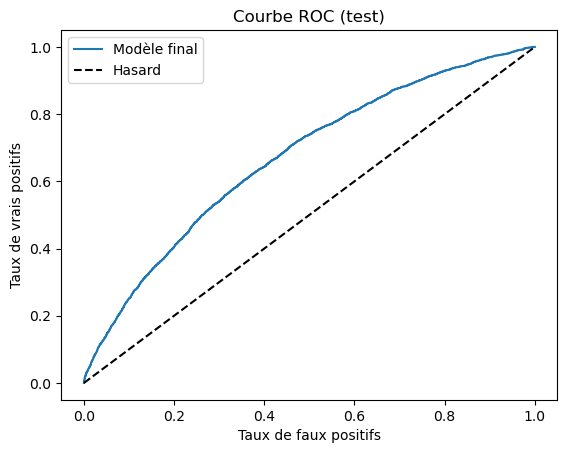

In [14]:
modele_final = Pipeline([('prep', preparation),
                         ('modele', HistGradientBoostingClassifier(random_state=42, **best_params))])
modele_final.fit(pd.concat([X_train, X_valid]), pd.concat([yb_train, yb_valid]))
proba_test = modele_final.predict_proba(X_test)[:, 1]
print('AUC test :', round(roc_auc_score(yb_test, proba_test), 3))
fpr, tpr, _ = roc_curve(yb_test, proba_test)
plt.plot(fpr, tpr, label='Modèle final')
plt.plot([0, 1], [0, 1], 'k--', label='Hasard')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC (test)')
plt.legend()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_6552\3408393783.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bilan = res.groupby('niveau').agg(lignes=('blesse', 'size'), taux_blessure=('blesse', 'mean'),


        lignes  taux_blessure  taux_grave
niveau                                   
faible   22737          0.050       0.024
moyen    13693          0.103       0.037
fort      6843          0.179       0.057


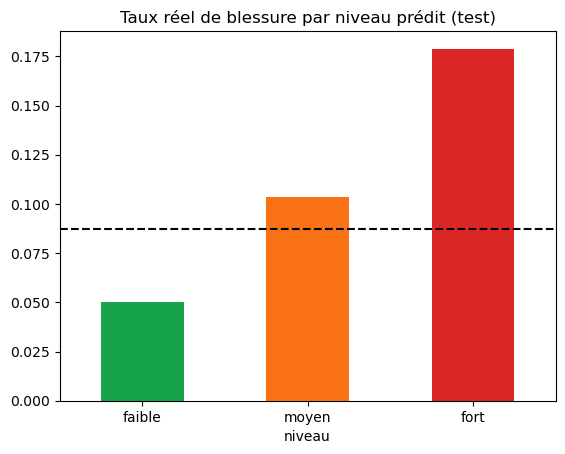

risque,aucun,faible,moyen,fort
niveau,,,,
faible,0.950,0.006,0.021,0.024
moyen,0.897,0.019,0.048,0.037
fort,0.821,0.032,0.090,0.057


In [15]:
res = test[['player', 'mois', 'team', 'risque']].copy()
res['proba'] = proba_test
res['niveau'] = niveau_de_risque(proba_test)
res['blesse'] = yb_test.values
bilan = res.groupby('niveau').agg(lignes=('blesse', 'size'), taux_blessure=('blesse', 'mean'),
                                  taux_grave=('risque', lambda s: (s == 'fort').mean()))
print(bilan.round(3))
bilan['taux_blessure'].plot.bar(color=['#16a34a', '#f97316', '#dc2626'])
plt.axhline(res['blesse'].mean(), color='k', ls='--')
plt.title('Taux réel de blessure par niveau prédit (test)')
plt.xticks(rotation=0)
plt.show()
pd.crosstab(res['niveau'], res['risque'], normalize='index').reindex(columns=ordre).round(3)

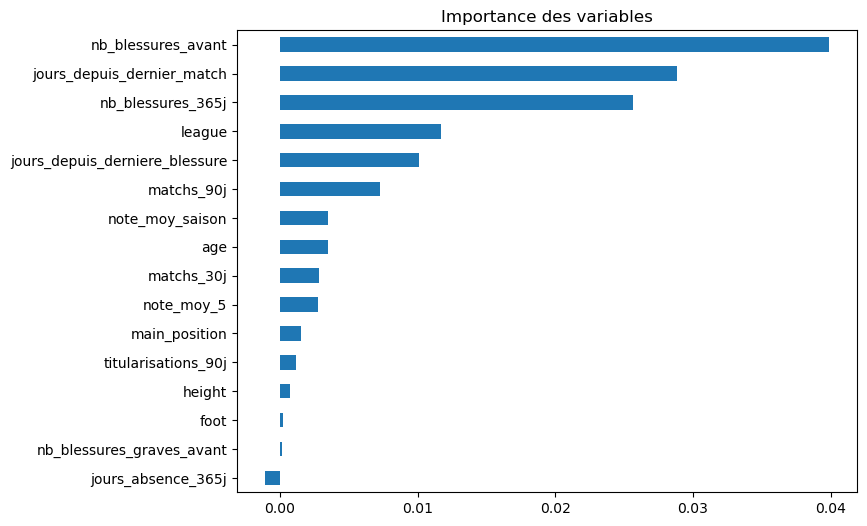

In [16]:
ech = X_test.sample(15000, random_state=42)
imp = permutation_importance(modele_final, ech, yb_test.loc[ech.index], scoring='roc_auc',
                             n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=ech.columns).sort_values()
importance.plot.barh(figsize=(8, 6), title='Importance des variables')
plt.show()

In [17]:
joblib.dump({'modele': modele_final, 'seuils': (seuil_1, seuil_2), 'colonnes': num_cols + cat_cols},
            os.path.join(os.path.dirname(F_DATA), 'modele_risque_blessure.pkl'))

['C:\\Users\\lenovo\\Downloads\\modele_risque_blessure.pkl']

In [ ]:
import unicodedata

def normaliser(t):
    t = unicodedata.normalize('NFKD', str(t)).encode('ascii', 'ignore').decode()
    return ' '.join(t.lower().split())

INDEX_JOUEURS = {}
for j in df['player'].unique():
    INDEX_JOUEURS.setdefault(normaliser(j), []).append(j)

def trouver_joueur(nom):
    cle = normaliser(nom)
    if cle in INDEX_JOUEURS:
        return INDEX_JOUEURS[cle][0], []
    contient = [j for k, js in INDEX_JOUEURS.items() if cle in k for j in js]
    if len(contient) == 1:
        return contient[0], []
    proches = difflib.get_close_matches(cle, list(INDEX_JOUEURS), n=5, cutoff=0.6)
    proches = contient + [INDEX_JOUEURS[p][0] for p in proches if INDEX_JOUEURS[p][0] not in contient]
    return None, proches[:5]

def predire(nom, mois):
    mois = mois.strip()
    trouve, proches = trouver_joueur(nom)
    if trouve is None:
        print(f'Joueur introuvable : {nom.strip()}. Vouliez-vous dire : {", ".join(proches)} ?')
        return
    nom = trouve
    ligne = df[(df['player'] == nom) & (df['mois'] == mois)]
    if ligne.empty:
        print(f'Pas de données pour {nom} en {mois} (ne jouait pas ou déjà blessé).')
        print('Mois disponibles :', ', '.join(df[df['player'] == nom]['mois'].tolist()[-12:]))
        return
    ligne = ligne.iloc[0]
    proba = modele_final.predict_proba(ligne[num_cols + cat_cols].to_frame().T)[:, 1][0]
    print(f'===== {nom} | {ligne["team"]} | {ligne["league"]} | {mois} =====')
    print(f'Âge : {ligne["age"]} | Poste : {ligne["main_position"]} | Matchs 30j : {ligne["matchs_30j"]} | Blessures 365j : {ligne["nb_blessures_365j"]}')
    print(f'PRÉDICTION : {proba:.1%} de risque de blessure, risque {str(niveau_de_risque(proba)[0]).upper()}')
    if ligne['jours_absence_mois_suivant'] > 0:
        print(f'RÉALITÉ    : BLESSÉ ({ligne["jours_absence_mois_suivant"]:.0f} jours, gravité {ligne["risque"]})')
        if blessures is not None:
            d = blessures[(blessures['player_ratings'] == nom) & (blessures['from_date'].dt.strftime('%Y-%m') == mois)]
            for _, b in d.iterrows():
                print(f'             {b["injury_reason"]} le {b["from_date"]:%d/%m/%Y}')
    else:
        print('RÉALITÉ    : PAS BLESSÉ')
    if mois < '2021-07':
        print('Attention : mois utilisé pour l entraînement, ce n est pas un vrai test.')

def chercher_joueurs(nom, n_max=20):
    cle = normaliser(nom)
    if not cle:
        return []
    contient = sorted({j for k, js in INDEX_JOUEURS.items() if cle in k for j in js})
    proches = [INDEX_JOUEURS[p][0] for p in difflib.get_close_matches(cle, list(INDEX_JOUEURS), n=5, cutoff=0.75)]
    return (contient + [p for p in proches if p not in contient])[:n_max]

def resume_joueur(j):
    d = df[df['player'] == j].sort_values('mois')
    der = d.iloc[-1]
    return f"{j} | {der['team']} ({der['league']}) | {d['mois'].iloc[0]} -> {d['mois'].iloc[-1]}"

def predire_interactif():
    # 1. Nom -> liste de joueurs
    candidats = []
    while not candidats:
        candidats = chercher_joueurs(input('Nom du joueur : '))
        if not candidats:
            print('Aucun joueur trouvé, réessaie.')
    # 2. Choix du joueur
    if len(candidats) == 1:
        joueur = candidats[0]
        print('Joueur trouvé :', resume_joueur(joueur))
    else:
        print(f'{len(candidats)} joueurs trouvés :')
        for i, j in enumerate(candidats, 1):
            print(f'  {i:>2}. {resume_joueur(j)}')
        while True:
            choix = input(f'Choisis un numéro (1-{len(candidats)}) : ').strip()
            if choix.isdigit() and 1 <= int(choix) <= len(candidats):
                break
            print('Numéro invalide.')
        joueur = candidats[int(choix) - 1]
        print('Joueur choisi :', joueur)
    # 3. Choix du mois
    mois_dispo = sorted(df.loc[df['player'] == joueur, 'mois'].unique())
    par_annee = {}
    for m in mois_dispo:
        par_annee.setdefault(m[:4], []).append(m[5:])
    print('Mois disponibles :')
    for annee, ms in par_annee.items():
        print(f'  {annee} : {" ".join(ms)}')
    while True:
        mois = input('Mois (AAAA-MM, ex 2022-11) : ').strip()
        if mois in mois_dispo:
            break
        print('Mois non disponible pour ce joueur, choisis-en un dans la liste.')
    # 4. Prédiction
    print()
    predire(joueur, mois)

# Tape le nom du joueur, choisis-le dans la liste, puis le mois
predire_interactif()